# TFG — Valoración de una Call Americana con Dividendos bajo Volatilidad con Cambio de Régimen (Markov)
**Objetivo del notebook:** construir un pipeline reproducible (nivel TFG) para comparar:
- **Árbol binomial** (referencia) *(opcional si lo añades después)*  
- **Monte Carlo estándar** (opción europea)  
- **Monte Carlo con Muestreo por Importancia (IS)** (opción europea)  
- **Longstaff–Schwartz (LSM)** (opción americana)  
- **LSM + IS (policy valuation)** (americana: se aprende la política con LSM estándar y se valora con IS)

**Qué se exporta:**
- Un CSV con todos los escenarios en `./outputs/resultados_tfg.csv`
- Gráficos en `./outputs/` (PNG) listos para incluir en la memoria.

> Nota de rigor: para una **call sin dividendos** (q=0), bajo supuestos estándar, el ejercicio anticipado no es óptimo y la call americana coincide con la europea. En este notebook ese hecho se usa como *sanity check* del pipeline.


In [16]:
# ===========================
# 0) Librerías y configuración
# ===========================
import numpy as np
import pandas as pd
import time
from dataclasses import dataclass
import matplotlib.pyplot as plt
from pathlib import Path

np.set_printoptions(suppress=True, precision=6)

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

print("Directorio de salida:", OUT_DIR.resolve())


Directorio de salida: C:\Users\Usuario\GitHub\ucm\TFG\outputs


## 1) Parámetros del experimento (elegidos “razonables” y defendibles)

Para que el capítulo de resultados quede limpio, trabajaremos con una rejilla pequeña pero informativa:

- **Moneyness (strikes)**: \(K \in \{90, 100, 110, 120\}\)
- **Vencimientos**: \(T \in \{0.25, 1, 2\}\) (3 meses, 1 año, 2 años)
- **Dos matrices de transición**:
  - **P persistente**: regímenes duraderos
  - **P menos persistente**: cambios más frecuentes
- **Volatilidades por régimen**: \(\sigma_L=18\%\), \(\sigma_H=40\%\)
- **Tipos**: \(r=3\%\), **dividend yield**: \(q=2\%\)

Con esto obtienes resultados comparables sin “inflar” el número de escenarios.


In [17]:
# ===========================
# 1) Parámetros del experimento
# ===========================
S0 = 100.0
r = 0.03
q_main = 0.02   # caso principal del TFG: con dividendos (call americana sí puede tener ejercicio anticipado)
q_sanity = 0.0  # sanity check: call americana = europea

sigma_L = 0.18
sigma_H = 0.40

# Matrices de transición (2 estados: 0=baja vol, 1=alta vol)
P_persistente = np.array([[0.95, 0.05],
                          [0.10, 0.90]])

P_menos_persistente = np.array([[0.85, 0.15],
                                [0.20, 0.80]])

Ps = {
    "persistente": P_persistente,
    "menos_persistente": P_menos_persistente
}

Ks = [90.0, 100.0, 110.0, 120.0]
Ts = [0.25, 1.0, 2.0]

# Discretización temporal (pasos por año)
steps_per_year = 252

# Número de trayectorias para LSM / MC
M_std = 50_000     # estándar
M_is  = 50_000     # IS (igual para comparar justicia)
seed_base = 2026

print("OK. Escenarios:", len(Ps)*len(Ks)*len(Ts))


OK. Escenarios: 24


## 2) Utilidades del modelo: cadena de Markov y simulación del subyacente

Bajo la medida neutral al riesgo:
\[
dS_t = (r-q)\,S_t\,dt + \sigma(X_t)\,S_t\,dW_t,
\]
donde \(X_t\) es una cadena de Markov en tiempo discreto con dos regímenes.

**Importante:** usamos la discretización exacta del GBM por paso:
\[
S_{t+\Delta t} = S_t \exp\Big((r-q-\tfrac{1}{2}\sigma^2)\Delta t + \sigma\sqrt{\Delta t}\,Z\Big).
\]


In [18]:
# ===========================
# 2) Modelo y simulación
# ===========================
@dataclass(frozen=True)
class RegimeParams:
    sigma: np.ndarray  # shape (2,)
    P: np.ndarray      # shape (2,2)

@dataclass(frozen=True)
class MarketParams:
    r: float
    q: float

def validate_params(regime: RegimeParams, market: MarketParams):
    sigma = np.asarray(regime.sigma, dtype=float)
    P = np.asarray(regime.P, dtype=float)
    if sigma.shape != (2,):
        raise ValueError("sigma debe tener shape (2,)")
    if np.any(sigma <= 0):
        raise ValueError("sigma debe ser > 0")
    if P.shape != (2,2):
        raise ValueError("P debe tener shape (2,2)")
    if np.any(P < 0) or not np.allclose(P.sum(axis=1), 1.0, atol=1e-12):
        raise ValueError("P debe ser estocástica por filas (filas suman 1)")

def simulate_markov_regimes(P: np.ndarray, n_paths: int, n_steps: int, x0: int = 0, seed: int = 42):
    #\"\"\"Simula X_{0..N} en {0,1} con matriz de transición P.\"\"\"
    rng = np.random.default_rng(seed)
    P = np.asarray(P, dtype=float)
    X = np.empty((n_paths, n_steps+1), dtype=np.int8)
    X[:, 0] = x0
    U = rng.random((n_paths, n_steps))
    p_to_0 = P[:, 0]
    for t in range(n_steps):
        prev = X[:, t]
        thr = p_to_0[prev]
        X[:, t+1] = (U[:, t] >= thr).astype(np.int8)
    return X

def stationary_dist_2state(P: np.ndarray):
    P = np.asarray(P, dtype=float)
    p01 = P[0,1]
    p10 = P[1,0]
    pi0 = p10 / (p01 + p10)
    pi1 = 1.0 - pi0
    return np.array([pi0, pi1])

def simulate_asset_paths_regime_switching(
    S0: float, T: float, n_steps: int, n_paths: int,
    market: MarketParams, regime: RegimeParams, x0: int = 0, seed: int = 42
):
    validate_params(regime, market)
    dt = T / n_steps
    t_grid = np.linspace(0.0, T, n_steps+1)
    X = simulate_markov_regimes(regime.P, n_paths, n_steps, x0=x0, seed=seed)

    rng = np.random.default_rng(seed+1)
    Z = rng.standard_normal((n_paths, n_steps))

    S = np.empty((n_paths, n_steps+1), dtype=float)
    S[:, 0] = S0

    r, q = market.r, market.q
    sig_states = np.asarray(regime.sigma, dtype=float)

    for t in range(n_steps):
        sig = sig_states[X[:, t]]
        drift = (r - q - 0.5*sig**2) * dt
        diff  = sig * np.sqrt(dt) * Z[:, t]
        S[:, t+1] = S[:, t] * np.exp(drift + diff)

    return t_grid, S, X


## 3) Monte Carlo para opción europea (estimador, SE y CI95)

Para una call europea:
\[
C^{Eu} = e^{-rT}\,\mathbb{E}\big[(S_T-K)^+\big].
\]

Reportaremos:
- estimación MC
- error estándar (SE)
- intervalo de confianza 95% (CI95)


In [19]:
# ===========================
# 3) Europea: MC estándar
# ===========================
def price_european_call_mc(S_T: np.ndarray, K: float, r: float, T: float):
    payoff = np.maximum(S_T - K, 0.0)
    disc = np.exp(-r*T)
    contrib = disc * payoff
    price = contrib.mean()
    se = contrib.std(ddof=1) / np.sqrt(contrib.size)
    ci_low = price - 1.96*se
    ci_high = price + 1.96*se
    return price, se, ci_low, ci_high


## 4) Muestreo por Importancia (IS) en europea: desplazamiento de normales

Simulamos \(Z_t^{(\lambda)} = Z_t + \lambda\), lo que “mueve” la distribución hacia escenarios más ITM.

El peso (likelihood ratio) por trayectoria es:
\[
W = \exp\Big(-\lambda \sum_{k=0}^{N-1} Z_k - \tfrac{1}{2}\lambda^2 N\Big).
\]

Estimador IS:
\[
\hat{C}^{IS} = e^{-rT}\frac{1}{M}\sum_{i=1}^M W^{(i)}(S_T^{(i)}-K)^+.
\]

Además, para la americana (LSM+IS) necesitaremos **pesos acumulados por tiempo** \(W_t\).


In [20]:
# ===========================
# 4) IS: simulación con pesos (finales y acumulados)
# ===========================
def choose_lambda_proxy(S0, K, r, q, T, sigma_L, sigma_H, P):
    #\"\"\"Heurística razonable: aproxima un tilt para llevar masa hacia el strike.\"\"\"
    pi = stationary_dist_2state(P)
    sig_bar = np.sqrt(pi[0]*sigma_L**2 + pi[1]*sigma_H**2)
    m0 = np.log(S0) + (r - q - 0.5*sig_bar**2)*T
    target = np.log(K)
    lam = (target - m0) / (sig_bar*np.sqrt(T))
    return float(lam)

def simulate_asset_paths_regime_switching_IS_with_cumweights(
    S0, T, n_steps, n_paths, market, regime, lam, x0=0, seed=42
):
    validate_params(regime, market)
    dt = T / n_steps
    t_grid = np.linspace(0.0, T, n_steps+1)

    X = simulate_markov_regimes(regime.P, n_paths, n_steps, x0=x0, seed=seed)

    rng = np.random.default_rng(seed+1)
    Z = rng.standard_normal((n_paths, n_steps))
    Z_tilt = Z + lam

    S = np.empty((n_paths, n_steps+1), dtype=float)
    S[:, 0] = S0

    # pesos acumulados: logW_{t+1} = logW_t + (-lam Z_t - 0.5 lam^2)
    logW = np.zeros((n_paths, n_steps+1), dtype=float)
    logw_step = -lam*Z - 0.5*(lam**2)

    r, q = market.r, market.q
    sig_states = np.asarray(regime.sigma, dtype=float)

    for t in range(n_steps):
        sig = sig_states[X[:, t]]
        drift = (r - q - 0.5*sig**2) * dt
        diff  = sig*np.sqrt(dt)*Z_tilt[:, t]
        S[:, t+1] = S[:, t] * np.exp(drift + diff)
        logW[:, t+1] = logW[:, t] + logw_step[:, t]

    W = np.exp(logW)
    return t_grid, S, X, W

def price_european_call_mc_weighted(S_T, W_T, K, r, T):
    payoff = np.maximum(S_T - K, 0.0)
    disc = np.exp(-r*T)
    contrib = disc * W_T * payoff
    price = contrib.mean()
    se = contrib.std(ddof=1) / np.sqrt(contrib.size)
    ci_low = price - 1.96*se
    ci_high = price + 1.96*se
    return price, se, ci_low, ci_high


## 5) Longstaff–Schwartz (LSM) para call americana: **política + valoración**

Para opciones americanas, el valor se formula como un problema de **parada óptima**. LSM aproxima el valor de continuación mediante regresión sobre funciones base (aquí, polinomios en \(S/K\)).  

**Salida clave para IS:** el índice de ejercicio \(\tau_i\) por trayectoria (política de ejercicio).

> Implementación: versión “cashflow-based”, estándar y estable.


In [21]:
# ===========================
# 5) LSM: política (tau_idx) + precio estándar
# ===========================
def _make_basis(x: np.ndarray, degree: int = 2) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    cols = [np.ones_like(x)]
    for d in range(1, degree+1):
        cols.append(x**d)
    return np.column_stack(cols)

def lsm_american_call_policy(
    S: np.ndarray,
    X: np.ndarray,
    K: float,
    r: float,
    T: float,
    basis_degree: int = 2,
    by_regime: bool = True,
    scale_by_strike: bool = True,
    min_reg_points: int = 200
):
    #\"\"\"Devuelve (tau_idx, CF, PV0, boundary).\"\"\"
    S = np.asarray(S, float)
    X = np.asarray(X)
    M, Np1 = S.shape
    N = Np1 - 1
    dt = T / N

    payoff = np.maximum(S - K, 0.0)

    CF = payoff[:, -1].copy()
    tau = np.full(M, N, dtype=int)

    boundary = {0: np.full(Np1, np.nan), 1: np.full(Np1, np.nan)}

    for t in range(N-1, 0, -1):
        alive = (tau > t)
        if not np.any(alive):
            break

        S_t = S[alive, t]
        X_t = X[alive, t]
        payoff_t = payoff[alive, t]

        itm = payoff_t > 0
        if not np.any(itm):
            continue

        tau_alive = tau[alive][itm]
        CF_alive = CF[alive][itm]
        # valor (en t) del flujo que ocurriría en tau_alive
        Y = CF_alive * np.exp(-r * (tau_alive - t) * dt)

        S_itm = S_t[itm]
        X_itm = X_t[itm]
        payoff_itm = payoff_t[itm]

        x_feat = (S_itm / K) if scale_by_strike else S_itm
        C_hat = np.zeros_like(Y)

        if by_regime:
            for state in (0, 1):
                mask = (X_itm == state)
                if mask.sum() < min_reg_points:
                    if mask.sum() > 0:
                        C_hat[mask] = Y[mask].mean()
                    continue
                A = _make_basis(x_feat[mask], degree=basis_degree)
                beta, *_ = np.linalg.lstsq(A, Y[mask], rcond=None)
                C_hat[mask] = A @ beta
        else:
            if x_feat.size >= min_reg_points:
                A = _make_basis(x_feat, degree=basis_degree)
                beta, *_ = np.linalg.lstsq(A, Y, rcond=None)
                C_hat = A @ beta
            else:
                C_hat[:] = Y.mean()

        exercise = payoff_itm >= C_hat

        alive_idx = np.flatnonzero(alive)
        itm_idx_global = alive_idx[np.flatnonzero(itm)]
        ex_global = itm_idx_global[exercise]

        CF[ex_global] = payoff[ex_global, t]
        tau[ex_global] = t

        # frontera aproximada por régimen: mínimo S donde se ejerce
        for state in (0,1):
            ms = (X_itm == state)
            if np.any(ms):
                S_state = S_itm[ms]
                ex_state = exercise[ms]
                if np.any(ex_state):
                    boundary[state][t] = np.nanmin(S_state[ex_state])

    PV0 = CF * np.exp(-r * tau * dt)
    payoff0 = max(S[0,0] - K, 0.0)
    PV0 = np.maximum(PV0, payoff0)

    return tau, CF, PV0, boundary

def price_american_call_lsm(
    S, X, K, r, T,
    basis_degree=2, by_regime=True, scale_by_strike=True, min_reg_points=200
):
    t0 = time.perf_counter()
    tau, CF, PV0, boundary = lsm_american_call_policy(
        S, X, K, r, T,
        basis_degree=basis_degree, by_regime=by_regime,
        scale_by_strike=scale_by_strike, min_reg_points=min_reg_points
    )
    price = PV0.mean()
    se = PV0.std(ddof=1)/np.sqrt(PV0.size)
    ci_low = price - 1.96*se
    ci_high = price + 1.96*se
    elapsed = time.perf_counter() - t0
    return price, se, ci_low, ci_high, elapsed, tau, boundary


## 6) Valoración de la política bajo IS (americana “LSM + IS”)

Una vez aprendida la política \(\tau_i\) con LSM estándar, la valoramos bajo IS:

\[
\hat{V}^{IS} = \frac{1}{M}\sum_{i=1}^M e^{-r \tau_i \Delta t} W_{\tau_i}^{(i)} (S_{\tau_i}^{(i)} - K)^+.
\]

Esto reduce varianza en escenarios donde IS concentra masa en zonas relevantes del payoff.


In [22]:
# ===========================
# 6) Americana: valoración de política bajo IS
# ===========================
def value_policy_under_IS(S, W, tau_idx, K, r, T):
    S = np.asarray(S, float)
    W = np.asarray(W, float)
    tau_idx = np.asarray(tau_idx, int)

    M, Np1 = S.shape
    N = Np1 - 1
    dt = T / N

    idx = np.arange(M)
    payoff_tau = np.maximum(S[idx, tau_idx] - K, 0.0)
    weight_tau = W[idx, tau_idx]
    disc_tau = np.exp(-r * tau_idx * dt)

    contrib = disc_tau * weight_tau * payoff_tau
    price = contrib.mean()
    se = contrib.std(ddof=1) / np.sqrt(M)
    ci_low = price - 1.96*se
    ci_high = price + 1.96*se
    return price, se, ci_low, ci_high


## 7) Sanity checks (mínimos y defendibles)

1) **Esperanza del subyacente**:
\[
\mathbb{E}[S_T] = S_0 e^{(r-q)T}
\]
(permite comprobar que el simulador está bien).

2) **Call americana sin dividendos** (\(q=0\)): no hay incentivo al ejercicio anticipado, luego:
\[
C^{Am} \approx C^{Eu}
\]
(en la práctica, pequeñas diferencias pueden aparecer por ruido de regresión, pero deben ser pequeñas y tender a 0 al aumentar M).

En el caso principal \(q=0.02\) sí puede aparecer ejercicio anticipado.


In [23]:
# ===========================
# 7) Sanity checks
# ===========================
def sanity_check_underlying_mean(S_T, S0, r, q, T):
    theo = S0*np.exp((r-q)*T)
    mc = S_T.mean()
    se = S_T.std(ddof=1)/np.sqrt(S_T.size)
    return theo, mc, se

def run_sanity(P_name="persistente", T=1.0, K=100.0, M=50_000, seed=123):
    P = Ps[P_name]
    regime = RegimeParams(sigma=np.array([sigma_L, sigma_H]), P=P)

    # q = 0 check
    market0 = MarketParams(r=r, q=q_sanity)
    n_steps = int(steps_per_year*T)

    _, S0q, X0q = simulate_asset_paths_regime_switching(S0, T, n_steps, M, market0, regime, seed=seed)
    eu, eu_se, *_ = price_european_call_mc(S0q[:,-1], K, r, T)
    am, am_se, *_ , elapsed, tau, _ = price_american_call_lsm(S0q, X0q, K, r, T)

    theo_ST, mc_ST, se_ST = sanity_check_underlying_mean(S0q[:,-1], S0, r, q_sanity, T)

    return {
        "P": P_name, "T": T, "K": K, "M": M,
        "E_ST_theo": theo_ST, "E_ST_mc": mc_ST, "E_ST_se": se_ST,
        "EU": eu, "EU_se": eu_se,
        "AM_LSM": am, "AM_se": am_se,
        "LSM_time": elapsed,
        "early_ex_rate": float(np.mean(tau < n_steps))
    }

san = run_sanity(P_name="persistente", T=1.0, K=100.0, M=30_000, seed=seed_base)
pd.DataFrame([san])


,P,T,K,M,E_ST_theo,E_ST_mc,E_ST_se,EU,EU_se,AM_LSM,AM_se,LSM_time,early_ex_rate
0,persistente,1.0,100.0,30000,103.045453,102.841028,0.163729,12.007582,0.112321,11.878855,0.093612,0.620933,0.239833


## 8) Experimento principal: comparativa completa y export

Para cada escenario:
- Simulamos bajo \(q=0.02\)
- Calculamos **Europea MC estándar**
- Calculamos **Europea MC+IS**
- Calculamos **Americana LSM** (y guardamos la política \(\tau\))
- Simulamos bajo IS con pesos acumulados y valoramos la **misma política** (**LSM+IS**)

Guardamos:
- precio, SE, CI95
- tiempo de cómputo
- métricas de eficiencia: **SE² × tiempo** (menor es mejor)


In [24]:
# ===========================
# 8) Runner del experimento + export
# ===========================
def run_experiment_grid():
    rows = []

    for P_name, P in Ps.items():
        regime = RegimeParams(sigma=np.array([sigma_L, sigma_H]), P=P)

        for T in Ts:
            n_steps = int(steps_per_year * T)
            market = MarketParams(r=r, q=q_main)

            # Simulación estándar (para EU estándar y LSM)
            seed_std = seed_base + int(1000*T) + (0 if P_name=="persistente" else 17)
            t0 = time.perf_counter()
            _, S_std, X_std = simulate_asset_paths_regime_switching(S0, T, n_steps, M_std, market, regime, seed=seed_std)
            sim_std_time = time.perf_counter() - t0

            # Pre-cálculos de IS (lambda elegido mirando K=110 como referencia de cola/OTM moderada)
            lam = choose_lambda_proxy(S0, 110.0, r, q_main, T, sigma_L, sigma_H, P)

            seed_is = seed_std + 999
            t1 = time.perf_counter()
            _, S_is, X_is, W_is = simulate_asset_paths_regime_switching_IS_with_cumweights(
                S0, T, n_steps, M_is, market, regime, lam=lam, seed=seed_is
            )
            sim_is_time = time.perf_counter() - t1

            # Por cada strike, precios y métricas
            for K in Ks:
                # Europea estándar
                eu_p, eu_se, eu_lo, eu_hi = price_european_call_mc(S_std[:,-1], K, r, T)

                # Europea IS (peso al final)
                W_T = W_is[:, -1]
                euis_p, euis_se, euis_lo, euis_hi = price_european_call_mc_weighted(S_is[:,-1], W_T, K, r, T)

                # Americana LSM (aprende política)
                am_p, am_se, am_lo, am_hi, am_time, tau_idx, boundary = price_american_call_lsm(
                    S_std, X_std, K, r, T, basis_degree=2, by_regime=True
                )

                # Americana LSM + IS (valora política bajo IS)
                t2 = time.perf_counter()
                amis_p, amis_se, amis_lo, amis_hi = value_policy_under_IS(S_is, W_is, tau_idx, K, r, T)
                amis_time = time.perf_counter() - t2

                # Métricas de eficiencia (SE^2 * tiempo)
                eff_lsm = (am_se**2) * am_time
                eff_lsm_is = (amis_se**2) * (amis_time + sim_is_time)  # incluye sim IS
                # (para el IS total, sumamos el tiempo de sim IS porque es coste real)
                # también guardamos tiempos separados para transparencia

                rows.append({
                    "P": P_name,
                    "T": T,
                    "K": K,
                    "M_std": M_std,
                    "M_is": M_is,
                    "steps": n_steps,
                    "lambda": lam,

                    "EU_MC": eu_p,
                    "EU_MC_SE": eu_se,
                    "EU_MC_CI_low": eu_lo,
                    "EU_MC_CI_high": eu_hi,

                    "EU_IS": euis_p,
                    "EU_IS_SE": euis_se,
                    "EU_IS_CI_low": euis_lo,
                    "EU_IS_CI_high": euis_hi,

                    "AM_LSM": am_p,
                    "AM_LSM_SE": am_se,
                    "AM_LSM_CI_low": am_lo,
                    "AM_LSM_CI_high": am_hi,
                    "LSM_time": am_time,
                    "sim_std_time": sim_std_time,

                    "AM_LSM_IS": amis_p,
                    "AM_LSM_IS_SE": amis_se,
                    "AM_LSM_IS_CI_low": amis_lo,
                    "AM_LSM_IS_CI_high": amis_hi,
                    "policy_val_time": amis_time,
                    "sim_is_time": sim_is_time,

                    "early_ex_rate": float(np.mean(tau_idx < n_steps)),

                    "eff_LSM": eff_lsm,
                    "eff_LSM_IS_total": eff_lsm_is,
                    "SE_ratio_IS_over_LSM": amis_se/am_se if am_se>0 else np.nan
                })

    return pd.DataFrame(rows)

df = run_experiment_grid()
df.head()


,P,T,K,M_std,M_is,steps,lambda,EU_MC,EU_MC_SE,EU_MC_CI_low,...,AM_LSM_IS,AM_LSM_IS_SE,AM_LSM_IS_CI_low,AM_LSM_IS_CI_high,policy_val_time,sim_is_time,early_ex_rate,eff_LSM,eff_LSM_IS_total,SE_ratio_IS_over_LSM
0,persistente,0.25,90.0,50000,50000,63,0.746526,11.737741,0.050800,11.638174,...,10.367088,5.816534,-1.033318,21.767494,0.002561,0.225699,0.47468,0.000182,7.722531,248.214909
1,persistente,0.25,100.0,50000,50000,63,0.746526,5.373601,0.038230,5.298671,...,9.327220,5.241094,-0.945324,19.599763,0.002230,0.225699,0.19816,0.000270,6.261018,158.574898
2,persistente,0.25,110.0,50000,50000,63,0.746526,1.974521,0.024295,1.926903,...,2.213631,0.898404,0.452758,3.974503,0.002070,0.225699,0.07506,0.000067,0.183840,41.157620
3,persistente,0.25,120.0,50000,50000,63,0.746526,0.620541,0.013860,0.593375,...,0.760894,0.373995,0.027864,1.493924,0.002010,0.225699,0.02648,0.000017,0.031850,29.379020
4,persistente,1.00,90.0,50000,50000,252,0.448517,16.227093,0.096497,16.037960,...,2.070068,0.551196,0.989723,3.150413,0.002881,0.859966,0.35152,0.004067,0.262148,9.655539


In [25]:
# Export a CSV
csv_path = OUT_DIR / "resultados_tfg.csv"
df.to_csv(csv_path, index=False)
print("Exportado:", csv_path.resolve())
print("Filas:", len(df))


Exportado: C:\Users\Usuario\GitHub\ucm\TFG\outputs\resultados_tfg.csv
Filas: 24


## 9) Gráficos listos para la memoria

Generamos 3 gráficos típicos de un TFG cuantitativo:

1) **SE** de LSM vs LSM+IS (americana) por strike  
2) **Ganancia de eficiencia** \((SE^2\times t)\) relativa  
3) **Tasa de ejercicio anticipado** por strike

Los guardamos en PNG en `./outputs/`.


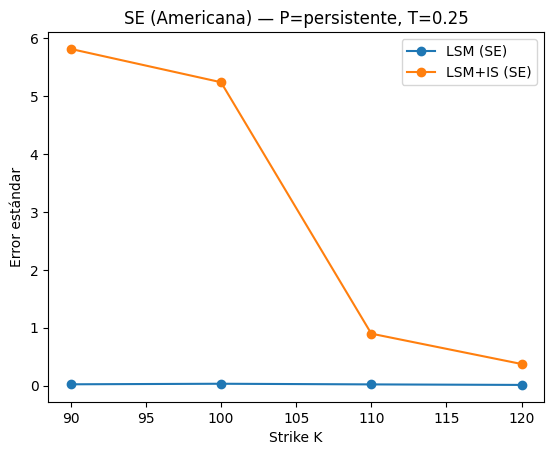

Guardado: outputs\se_americana_P-persistente_T-0.25.png


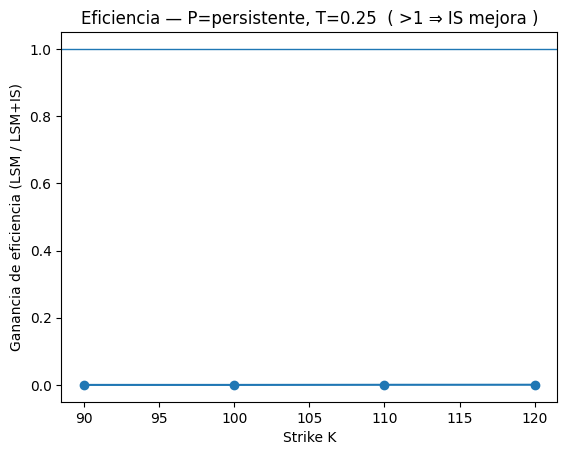

Guardado: outputs\eficiencia_gain_P-persistente_T-0.25.png


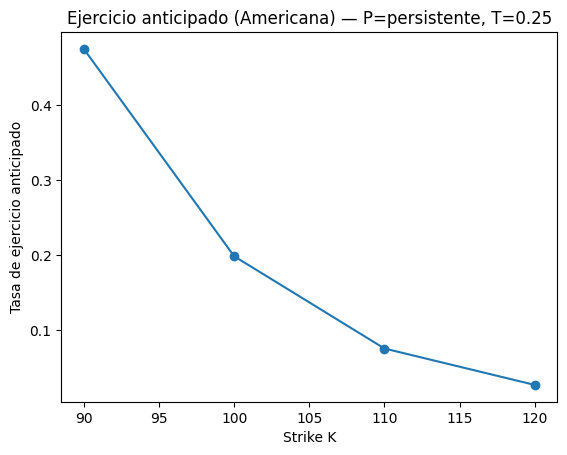

Guardado: outputs\early_ex_rate_P-persistente_T-0.25.png


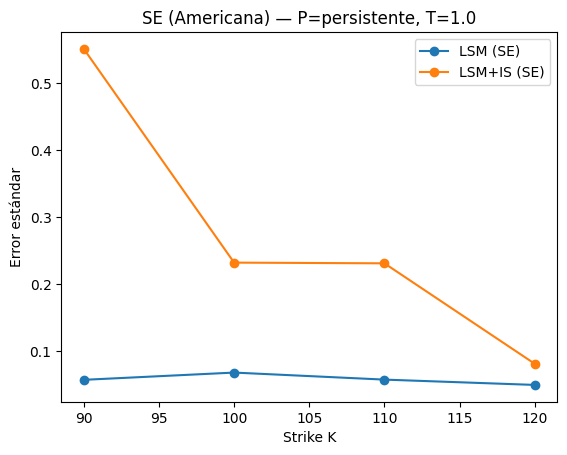

Guardado: outputs\se_americana_P-persistente_T-1.0.png


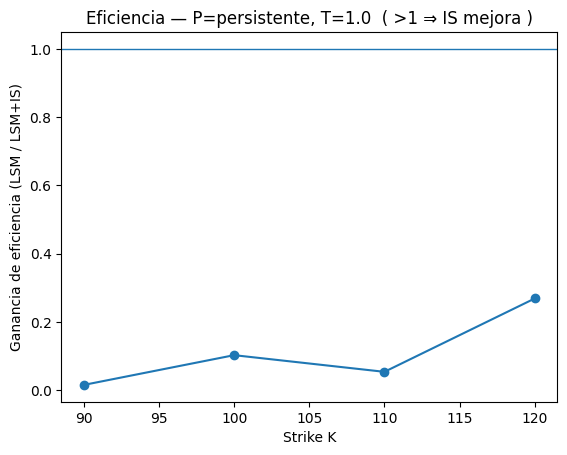

Guardado: outputs\eficiencia_gain_P-persistente_T-1.0.png


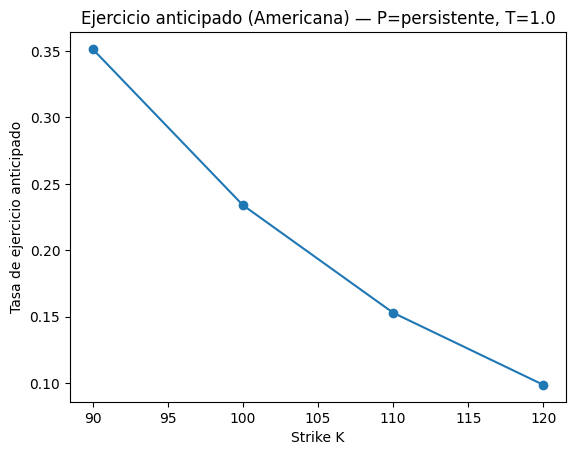

Guardado: outputs\early_ex_rate_P-persistente_T-1.0.png


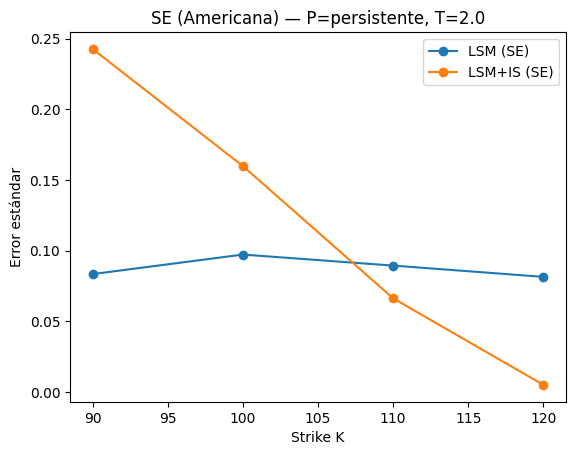

Guardado: outputs\se_americana_P-persistente_T-2.0.png


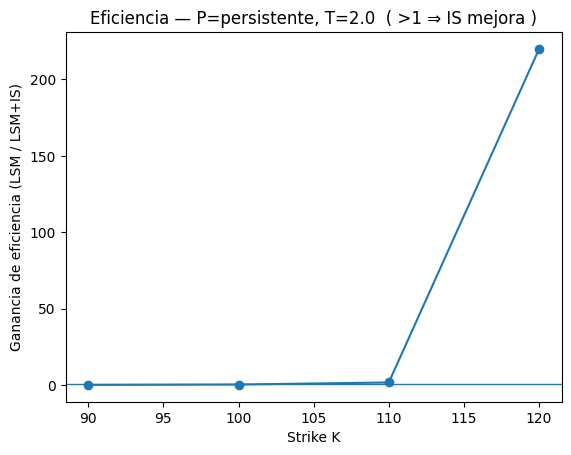

Guardado: outputs\eficiencia_gain_P-persistente_T-2.0.png


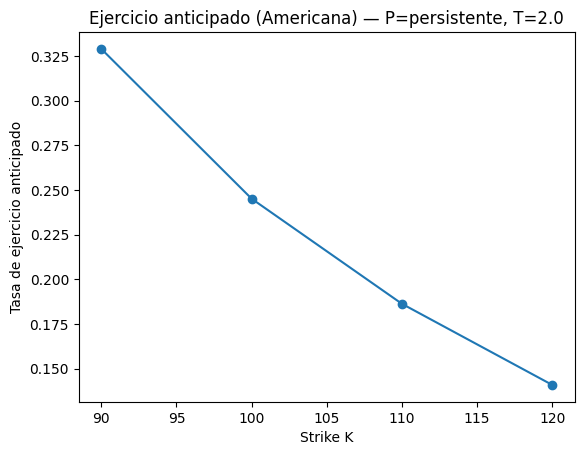

Guardado: outputs\early_ex_rate_P-persistente_T-2.0.png


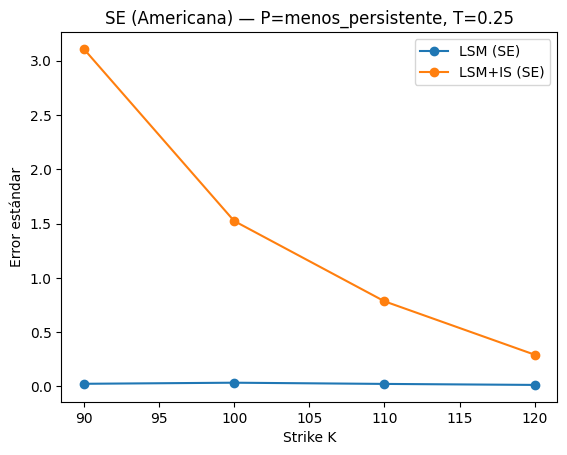

Guardado: outputs\se_americana_P-menos_persistente_T-0.25.png


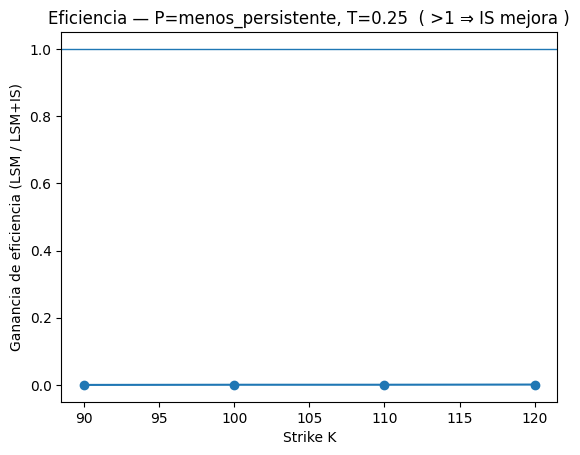

Guardado: outputs\eficiencia_gain_P-menos_persistente_T-0.25.png


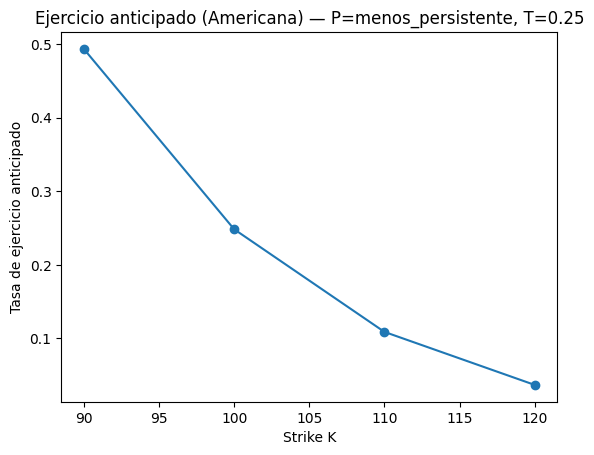

Guardado: outputs\early_ex_rate_P-menos_persistente_T-0.25.png


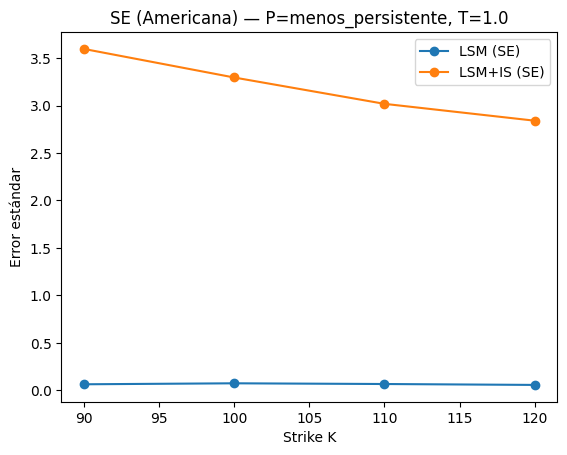

Guardado: outputs\se_americana_P-menos_persistente_T-1.0.png


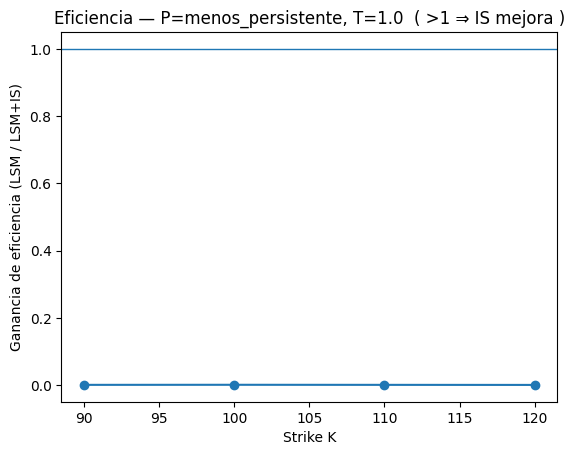

Guardado: outputs\eficiencia_gain_P-menos_persistente_T-1.0.png


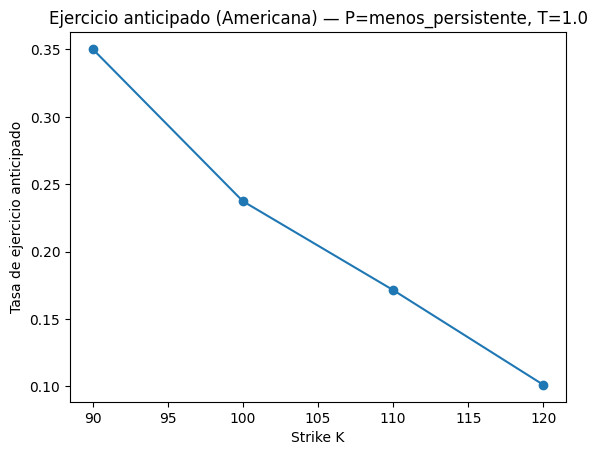

Guardado: outputs\early_ex_rate_P-menos_persistente_T-1.0.png


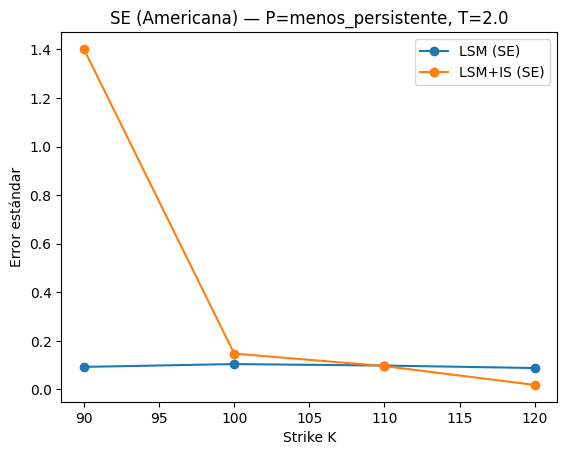

Guardado: outputs\se_americana_P-menos_persistente_T-2.0.png


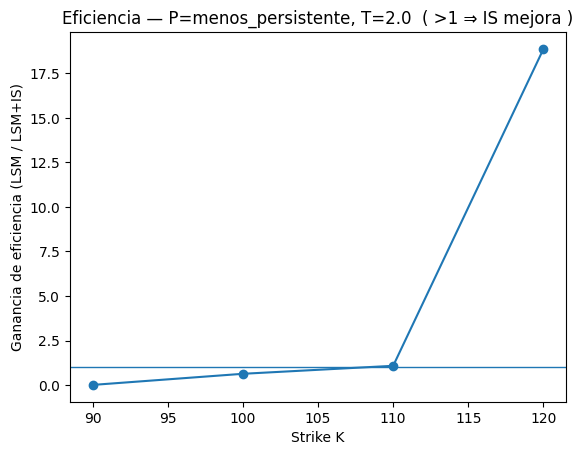

Guardado: outputs\eficiencia_gain_P-menos_persistente_T-2.0.png


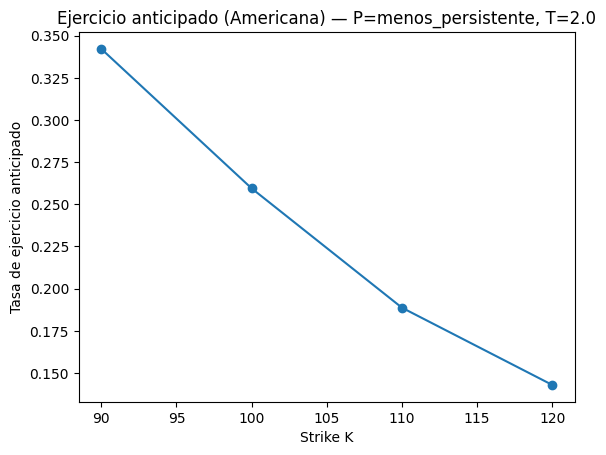

Guardado: outputs\early_ex_rate_P-menos_persistente_T-2.0.png


In [26]:
# ===========================
# 9) Gráficos
# ===========================
def plot_se_by_K(df, P_name, T):
    d = df[(df["P"]==P_name) & (df["T"]==T)].sort_values("K")
    plt.figure()
    plt.plot(d["K"], d["AM_LSM_SE"], marker="o", label="LSM (SE)")
    plt.plot(d["K"], d["AM_LSM_IS_SE"], marker="o", label="LSM+IS (SE)")
    plt.xlabel("Strike K")
    plt.ylabel("Error estándar")
    plt.title(f"SE (Americana) — P={P_name}, T={T}")
    plt.legend()
    out = OUT_DIR / f"se_americana_P-{P_name}_T-{T}.png"
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Guardado:", out)

def plot_efficiency_gain(df, P_name, T):
    d = df[(df["P"]==P_name) & (df["T"]==T)].sort_values("K")
    # eficiencia = SE^2 * tiempo; menor es mejor
    gain = d["eff_LSM"] / d["eff_LSM_IS_total"]
    plt.figure()
    plt.plot(d["K"], gain, marker="o")
    plt.axhline(1.0, linewidth=1)
    plt.xlabel("Strike K")
    plt.ylabel("Ganancia de eficiencia (LSM / LSM+IS)")
    plt.title(f"Eficiencia — P={P_name}, T={T}  ( >1 ⇒ IS mejora )")
    out = OUT_DIR / f"eficiencia_gain_P-{P_name}_T-{T}.png"
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Guardado:", out)

def plot_early_exercise(df, P_name, T):
    d = df[(df["P"]==P_name) & (df["T"]==T)].sort_values("K")
    plt.figure()
    plt.plot(d["K"], d["early_ex_rate"], marker="o")
    plt.xlabel("Strike K")
    plt.ylabel("Tasa de ejercicio anticipado")
    plt.title(f"Ejercicio anticipado (Americana) — P={P_name}, T={T}")
    out = OUT_DIR / f"early_ex_rate_P-{P_name}_T-{T}.png"
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Guardado:", out)

# Generamos gráficos para un subconjunto representativo
for P_name in Ps.keys():
    for T in Ts:
        plot_se_by_K(df, P_name, T)
        plot_efficiency_gain(df, P_name, T)
        plot_early_exercise(df, P_name, T)


## 10) Tablas resumen (para pegar en la memoria)

Te dejo una tabla resumen por \(T\) y \(P\), agregando por strike.

- **Precio y SE** (LSM vs LSM+IS)
- **Ganancia de eficiencia media**


In [27]:
# ===========================
# 10) Tablas resumen
# ===========================
summary_cols = [
    "P","T","K",
    "AM_LSM","AM_LSM_SE",
    "AM_LSM_IS","AM_LSM_IS_SE",
    "SE_ratio_IS_over_LSM",
    "eff_LSM","eff_LSM_IS_total",
    "early_ex_rate"
]

df_summary = df[summary_cols].copy()
df_summary.head()


,P,T,K,AM_LSM,AM_LSM_SE,AM_LSM_IS,AM_LSM_IS_SE,SE_ratio_IS_over_LSM,eff_LSM,eff_LSM_IS_total,early_ex_rate
0,persistente,0.25,90.0,14.928339,0.023433,10.367088,5.816534,248.214909,0.000182,7.722531,0.47468
1,persistente,0.25,100.0,5.351340,0.033051,9.327220,5.241094,158.574898,0.000270,6.261018,0.19816
2,persistente,0.25,110.0,1.977141,0.021828,2.213631,0.898404,41.157620,0.000067,0.183840,0.07506
3,persistente,0.25,120.0,0.623049,0.012730,0.760894,0.373995,29.379020,0.000017,0.031850,0.02648
4,persistente,1.00,90.0,20.519986,0.057086,2.070068,0.551196,9.655539,0.004067,0.262148,0.35152


In [28]:
# Resumen agregado: ganancia media por (P,T)
agg = (df.assign(eff_gain=lambda d: d["eff_LSM"]/d["eff_LSM_IS_total"])
         .groupby(["P","T"])
         .agg(
             eff_gain_mean=("eff_gain","mean"),
             eff_gain_median=("eff_gain","median"),
             se_ratio_mean=("SE_ratio_IS_over_LSM","mean"),
             early_ex_mean=("early_ex_rate","mean")
         )
         .reset_index()
)
agg


,P,T,eff_gain_mean,eff_gain_median,se_ratio_mean,early_ex_mean
0,menos_persistente,0.25,0.000617,0.000608,55.502141,0.221850
1,menos_persistente,1.00,0.000540,0.000536,49.539238,0.215055
2,menos_persistente,2.00,5.148502,0.855462,4.419966,0.233310
3,persistente,0.25,0.000245,0.000205,119.331612,0.193595
4,persistente,1.00,0.110214,0.078281,4.683822,0.209245
5,persistente,2.00,55.598350,1.110747,1.339482,0.225240


In [29]:
# Export de las tablas resumen
df_summary_path = OUT_DIR / "tabla_resumen_por_escenario.csv"
agg_path = OUT_DIR / "tabla_resumen_agregada.csv"

df_summary.to_csv(df_summary_path, index=False)
agg.to_csv(agg_path, index=False)

print("Exportado:", df_summary_path.resolve())
print("Exportado:", agg_path.resolve())


Exportado: C:\Users\Usuario\GitHub\ucm\TFG\outputs\tabla_resumen_por_escenario.csv
Exportado: C:\Users\Usuario\GitHub\ucm\TFG\outputs\tabla_resumen_agregada.csv
